# 04 — Score d'appétence

**Projet :** Segmentation et score d'appétence d'une base clients retail
**Auteure :** Danielle OUATTARA

**Objectif :** estimer, pour chaque client, sa probabilité de répondre à la prochaine campagne, afin de ne contacter que les plus réceptifs.

| Étape | Contenu |
|---|---|
| 1 | Import |
| 2 | Choix des variables |
| 3 | Séparation apprentissage / test |
| 4 | Modèle : régression logistique |
| 5 | Qualité du modèle (AUC) |
| 6 | Variables déterminantes |
| 7 | Courbe de gains : combien de répondants capte-t-on en ciblant les mieux scorés ? |
| 8 | Score de toute la base et export |

**Méthode en une phrase :** la régression logistique apprend, sur une partie des clients, le lien entre leurs caractéristiques et leur réponse à la dernière campagne ; on vérifie ensuite sur des clients qu'elle n'a jamais vus qu'elle classe correctement les répondants en tête.

## 1. Import

In [1]:
import pandas as pd                                         # manipulation de tableaux
import numpy as np                                          # calculs numériques
import matplotlib.pyplot as plt                             # graphiques
from sklearn.model_selection import train_test_split        # séparation apprentissage / test
from sklearn.preprocessing import StandardScaler            # standardisation
from sklearn.linear_model import LogisticRegression         # régression logistique
from sklearn.pipeline import make_pipeline                  # enchaîne standardisation et modèle
from sklearn.metrics import roc_auc_score, roc_curve         # mesure de la qualité du score

pd.set_option("display.max_columns", None)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
COULEUR = "#1F4E79"

df = pd.read_csv("../outputs/clients_segmentes.csv")         # base segmentée par le notebook 03
df = df[df["Nom_segment"] != "Non classé (profil incohérent)"].copy()   # on écarte les 4 profils incohérents
print(df.shape)                                              # on attend 2 228 lignes
print(f"Taux de réponse : {df['Response'].mean():.1%}")      # environ 15 %

(2228, 51)
Taux de réponse : 14.9%


## 2. Choix des variables

Le notebook 02 a montré que les signaux les plus forts sont **l'historique de campagnes acceptées** et **la récence du dernier achat**. On y ajoute les variables de profil et de comportement.

La variable à prédire est `Response` : 1 si le client a répondu à la dernière campagne, 0 sinon.

In [2]:
df["En_couple"] = (df["Situation"] == "En couple").astype(int)   # 1 si en couple, 0 sinon
df["Depense_log"] = np.log1p(df["Depense_totale"])                # dépense en logarithme, comme pour la segmentation

variables = {                                                     # nom technique : libellé en français
    "Recency": "Récence du dernier achat",
    "Nb_campagnes_acceptees": "Campagnes déjà acceptées",
    "Income": "Revenu",
    "Depense_log": "Dépense totale",
    "Achats_total": "Nombre d'achats",
    "Nb_enfants": "Nombre d'enfants",
    "En_couple": "En couple",
    "Part_promo": "Part des achats en promotion",
    "Part_web": "Part des achats sur le web",
    "Part_catalogue": "Part des achats par catalogue",
    "NumWebVisitsMonth": "Visites web par mois",
    "Anciennete_mois": "Ancienneté client",
    "Age": "Âge",
}
X = df[list(variables)]                                           # tableau des variables explicatives
y = df["Response"]                                                # variable à prédire
print(X.shape, y.mean().round(3))

(2228, 13) 0.149


## 3. Séparation apprentissage / test

Le modèle apprend sur 70 % des clients et il est évalué sur les 30 % restants, qu'il n'a jamais vus. Cela évite de surestimer sa qualité. Le paramètre `stratify` garantit le même taux de répondants (environ 15 %) dans les deux groupes.

In [3]:
X_app, X_test, y_app, y_test = train_test_split(               # découpe les données en deux
    X, y, test_size=0.3,                                        # 30 % pour le test
    stratify=y,                                                 # même proportion de répondants dans les deux parties
    random_state=42)                                            # fixe le hasard, pour des résultats reproductibles
print(f"Apprentissage : {len(X_app)} clients, {y_app.mean():.1%} de répondants")
print(f"Test          : {len(X_test)} clients, {y_test.mean():.1%} de répondants")

Apprentissage : 1559 clients, 14.9% de répondants
Test          : 669 clients, 14.9% de répondants


## 4. Modèle : régression logistique

Seuls 15 % des clients ont répondu. Un modèle naïf qui prédit toujours « ne répond pas » aurait raison 85 fois sur 100 sans rien apprendre. L'option `class_weight="balanced"` donne plus de poids aux répondants pendant l'apprentissage, pour que le modèle apprenne vraiment à les reconnaître.

In [4]:
modele = make_pipeline(                                          # enchaîne deux étapes :
    StandardScaler(),                                            # 1. standardisation des variables
    LogisticRegression(class_weight="balanced", max_iter=1000))  # 2. régression logistique
modele.fit(X_app, y_app)                                         # apprentissage sur 70 % des clients

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Recency','Nb_campagnes_acceptees','Income',...,'NumWebVisitsMonth', 'Anciennete_mois','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 5. Qualité du modèle

L'**AUC** mesure la capacité du modèle à classer un répondant devant un non-répondant : 0,5 correspond au hasard, 1 à un classement parfait. Au-delà de 0,8, le score est considéré comme bon pour un usage marketing.

In [5]:
score_test = modele.predict_proba(X_test)[:, 1]                  # probabilité de réponse estimée pour chaque client test
auc = roc_auc_score(y_test, score_test)                          # calcul de l'AUC
print(f"AUC sur les clients test : {auc:.2f}")

AUC sur les clients test : 0.90


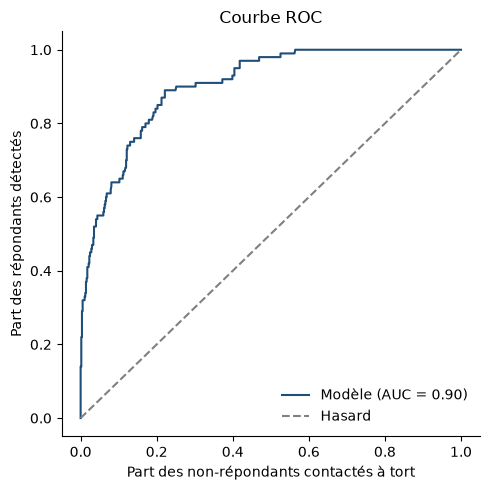

In [6]:
fpr, tpr, _ = roc_curve(y_test, score_test)                      # points de la courbe ROC
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color=COULEUR, label=f"Modèle (AUC = {auc:.2f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Hasard")   # diagonale = tirage au hasard
ax.set_xlabel("Part des non-répondants contactés à tort")
ax.set_ylabel("Part des répondants détectés")
ax.set_title("Courbe ROC")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../outputs/figures/04_roc.png", dpi=150)
plt.show()

> **Constat :** l'AUC atteint 0,90 sur des clients que le modèle n'a jamais vus : quand on compare un répondant et un non-répondant pris au hasard, le modèle place le répondant devant dans 90 % des cas. C'est un score de très bonne qualité pour un usage marketing.

## 6. Variables déterminantes

Les variables ayant été standardisées, les coefficients sont comparables entre eux : plus un coefficient est éloigné de zéro, plus la variable pèse. Un coefficient positif augmente la probabilité de réponse, un coefficient négatif la diminue.

In [13]:
coefficients = pd.Series(modele[-1].coef_[0],                    # coefficients de la régression
                         index=list(variables.values()))         # avec les libellés en français
coefficients = coefficients.sort_values()                        # du plus négatif au plus positif
coefficients.round(2)

Récence du dernier achat        -0.89
En couple                       -0.56
Nombre d'enfants                -0.55
Nombre d'achats                 -0.50
Dépense totale                  -0.05
Âge                              0.02
Visites web par mois             0.05
Revenu                           0.34
Part des achats en promotion     0.49
Part des achats sur le web       0.73
Campagnes déjà acceptées         0.95
Ancienneté client                0.97
Part des achats par catalogue    0.98
dtype: float64

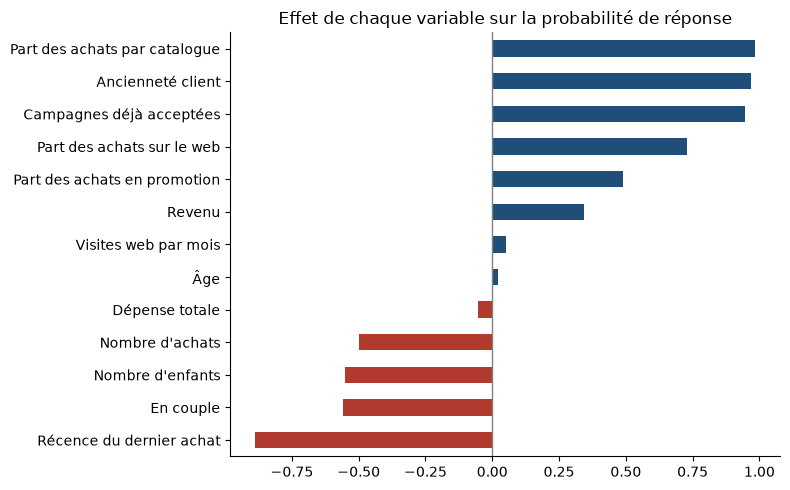

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
couleurs = [COULEUR if c > 0 else "#B03A2E" for c in coefficients]   # bleu si effet positif, rouge si négatif
coefficients.plot(kind="barh", ax=ax, color=couleurs)
ax.axvline(0, color="grey", linewidth=1)
ax.set_title("Effet de chaque variable sur la probabilité de réponse")
plt.tight_layout()
plt.savefig("../outputs/figures/04_variables.png", dpi=150)
plt.show()

> **Constat :** la probabilité de réponse augmente surtout avec la part des achats par catalogue, l'ancienneté du client et le nombre de campagnes déjà acceptées, puis avec la part des achats sur le web et en promotion. Elle diminue nettement avec la récence du dernier achat (un client qui n'a pas acheté depuis longtemps répond moins), le fait de vivre en couple et le nombre d'enfants. Certaines variables étant liées entre elles (nombre d'achats, dépense, revenu), leurs coefficients se lisent ensemble et non isolément : le nombre d'achats négatif ne signifie pas qu'un client fidèle répond moins, mais qu'à canal et profil égaux, la fréquence n'apporte pas d'information supplémentaire.

## 7. Courbe de gains

C'est l'indicateur le plus utile pour le marketing. On classe les clients test du mieux scoré au moins bien scoré, puis on les découpe en 10 tranches de même taille (déciles). On regarde quelle part des répondants on aurait touchée en ne contactant que les premières tranches.

In [9]:
gains = pd.DataFrame({"score": score_test, "reponse": y_test.values})   # score et réponse réelle des clients test
gains = gains.sort_values("score", ascending=False).reset_index(drop=True)   # du mieux scoré au moins bien scoré
gains["decile"] = pd.qcut(gains.index, 10, labels=range(1, 11))   # tranche 1 = les 10 % les mieux scorés

table_gains = gains.groupby("decile", observed=True).agg(         # une ligne par décile
    clients=("reponse", "count"),                                 # nombre de clients
    repondants=("reponse", "sum"),                                # nombre de répondants
    taux_reponse=("reponse", "mean"))                             # taux de réponse du décile
table_gains["part_base_cumulee"] = table_gains["clients"].cumsum() / table_gains["clients"].sum()
table_gains["part_repondants_cumulee"] = table_gains["repondants"].cumsum() / table_gains["repondants"].sum()
table_gains["lift"] = table_gains["taux_reponse"] / gains["reponse"].mean()   # combien de fois mieux que la moyenne
table_gains.round(2)

,clients,repondants,taux_reponse,part_base_cumulee,part_repondants_cumulee,lift
decile,,,,,,
1,67,48,0.72,0.1,0.48,4.79
2,67,20,0.30,0.2,0.68,2.00
3,67,17,0.25,0.3,0.85,1.70
4,67,6,0.09,0.4,0.91,0.60
5,67,6,0.09,0.5,0.97,0.60
6,66,2,0.03,0.6,0.99,0.20
7,67,1,0.01,0.7,1.00,0.10
8,67,0,0.00,0.8,1.00,0.00
9,67,0,0.00,0.9,1.00,0.00


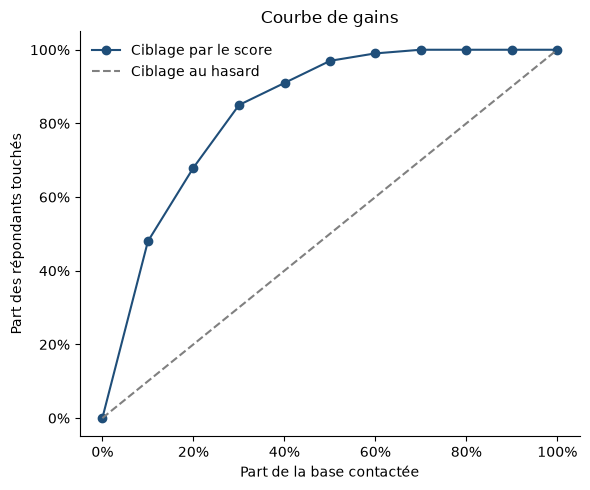

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
x = np.r_[0, table_gains["part_base_cumulee"]]                    # part de la base contactée, en partant de 0
y_gain = np.r_[0, table_gains["part_repondants_cumulee"]]         # part des répondants touchés
ax.plot(x, y_gain, marker="o", color=COULEUR, label="Ciblage par le score")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Ciblage au hasard")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Part de la base contactée")
ax.set_ylabel("Part des répondants touchés")
ax.set_title("Courbe de gains")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("../outputs/figures/04_gains.png", dpi=150)
plt.show()

In [11]:
top30 = table_gains.loc[3, "part_repondants_cumulee"]             # part des répondants touchés avec les 3 premiers déciles
print(f"En contactant les 30 % de clients les mieux scorés, on touche {top30:.0%} des répondants.")

En contactant les 30 % de clients les mieux scorés, on touche 85% des répondants.


> **Constat :** le ciblage par le score est très efficace. Les 10 % de clients les mieux scorés répondent à 72 %, soit 4,8 fois plus que la moyenne, et regroupent à eux seuls 48 % des répondants. En contactant les 30 % les mieux scorés, on touche 85 % des répondants ; à 50 %, on en touche 97 %. Les trois derniers déciles ne contiennent aucun répondant.

## 8. Score de toute la base et export

Le modèle est maintenant appliqué à l'ensemble des clients. Chaque client reçoit un score (probabilité de réponse) et un décile, réutilisés pour la simulation de ROI (notebook 05) et le dashboard.

In [12]:
df["Score"] = modele.predict_proba(df[list(variables)])[:, 1]     # probabilité de réponse pour chaque client
df["Decile_score"] = pd.qcut(df["Score"].rank(method="first", ascending=False),   # rang du client, du mieux au moins bien scoré
                             10, labels=range(1, 11)).astype(int)                # découpé en 10 tranches
df.to_csv("../outputs/clients_scores.csv", index=False)           # base utilisée par le notebook 05 et le dashboard
(df.groupby("Nom_segment")["Score"].mean()                        # score moyen par segment
   .sort_values(ascending=False).round(3))

Nom_segment
Clients premium                      0.440
Réguliers amateurs de vin            0.360
Familles chasseuses de promotions    0.337
Petits budgets occasionnels          0.201
Name: Score, dtype: float64

## Synthèse

Le score d'appétence classe très bien les clients (AUC de 0,90). Les signaux les plus forts sont l'historique de campagnes acceptées, l'ancienneté, la récence du dernier achat et l'usage du catalogue et du web. Concrètement, une campagne envoyée aux 30 % de clients les mieux scorés toucherait 85 % des répondants, pour moins d'un tiers des contacts.

Le score complète la segmentation : les clients premium ont le score moyen le plus élevé, les petits budgets occasionnels le plus faible. Mais chaque segment contient des clients bien scorés, ce qui permet de cibler finement à l'intérieur de chacun.

**Limite :** le modèle est entraîné sur une seule campagne. Avant un usage réel, il faudrait le valider sur une campagne suivante.

**Limite complémentaire :** le score sert à classer les clients, pas à prédire un taux exact. Le rééquilibrage des classes pendant l'apprentissage gonfle les probabilités (score moyen d'environ 0,34 pour un taux de réponse réel de 15 %) ; on raisonne donc en déciles, comme dans la courbe de gains.